# 05 · Fuentes externas: Banco Mundial y OWID (R3 · P3 · P7)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere `02_calidad` y `03_dw_estrella`.

1. **Descargar** dos fuentes externas (capa cruda):
   - **Banco Mundial** (API v2): % de población de 65 años o más, PIB per cápita (PPA) y grupo de ingreso de cada país, año 2019 (antes de la pandemia).
   - **Our World in Data (OWID)**: % de la población vacunada, por país y día.
2. **Cruzar por código ISO3** con el Data Warehouse e informar **cuántos países cruzan, cuáles no y por qué**.
3. **Cargar** las dos fuentes en el DW: `dim_pais` (país con indicadores del Banco Mundial y su índice de calidad) y `fact_vacunacion` (país × día).
4. Responder **P3** (letalidad y vacunación) y **P7** (población de 65+ y mortalidad).

## Setup

In [1]:
import os
import json
import shutil
import sqlite3
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/proyecto-gestion-datos-2026'
LIMPIOS = os.path.join(PROYECTO, 'data', 'clean')
EXTERNAS = '/content/datos_crudos/externas'      # capa cruda de las fuentes externas
os.makedirs(EXTERNAS, exist_ok=True)

# Trabajamos sobre una copia local del DW y al final la devolvemos a Drive
shutil.copy(os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'), '/content/covid_dw.db')
dw = sqlite3.connect('/content/covid_dw.db')

entidades_especiales = ['Diamond Princess', 'MS Zaandam', 'Summer Olympics 2020', 'Winter Olympics 2022', 'Antarctica']

## 1 · Descarga (capa cruda)
Igual que en `01_ingesta`: `requests.get()` y guardar el archivo tal cual llega. Si el archivo ya existe, no se vuelve a bajar.

In [2]:
def descargar(url, ruta):
    if not os.path.exists(ruta):
        response = requests.get(url)
        if response.status_code != 200:
            print('ERROR al descargar', url)
            return
        with open(ruta, 'wb') as f:
            f.write(response.content)
    print(f'{os.path.basename(ruta):40s} {os.path.getsize(ruta) / 1e6:6.2f} MB')

BM = 'https://api.worldbank.org/v2/'
indicadores = {'SP.POP.65UP.TO.ZS': 'pob_65_pct',     # población de 65 años o más (% del total)
               'NY.GDP.PCAP.PP.KD': 'pib_pc_ppa'}     # PIB per cápita, PPA (US$ internacionales constantes)

descargar(BM + 'country?format=json&per_page=400', os.path.join(EXTERNAS, 'wb_paises.json'))
for codigo in indicadores:
    descargar(BM + f'country/all/indicator/{codigo}?format=json&date=2019&per_page=20000',
              os.path.join(EXTERNAS, f'wb_{codigo}.json'))

descargar('https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/vaccinations/vaccinations.csv',
          os.path.join(EXTERNAS, 'owid_vacunacion.csv'))

wb_paises.json                             0.03 MB
wb_SP.POP.65UP.TO.ZS.json                  0.01 MB
wb_NY.GDP.PCAP.PP.KD.json                  0.01 MB
owid_vacunacion.csv                       14.38 MB


## 2 · Banco Mundial
La API responde un JSON con dos partes: `[información de la página, lista de registros]`. Nos quedamos con la segunda.

In [3]:
with open(os.path.join(EXTERNAS, 'wb_paises.json')) as f:
    j = json.load(f)
paises_bm = pd.DataFrame(j[1])

# La lista trae también agregados ("World", "Latin America & Caribbean"...): se excluyen
paises_bm['region_bm'] = paises_bm['region'].apply(lambda d: d['value'])
paises_bm = paises_bm[paises_bm['region_bm'] != 'Aggregates']

grupo = {'HIC': 'Alto', 'UMC': 'Medio alto', 'LMC': 'Medio bajo', 'LIC': 'Bajo'}
bm = pd.DataFrame({'iso3': paises_bm['id'],
                   'region_bm': paises_bm['region_bm'],
                   'grupo_ingreso': paises_bm['incomeLevel'].apply(lambda d: d['id']).map(grupo)})

for codigo, nombre in indicadores.items():
    with open(os.path.join(EXTERNAS, f'wb_{codigo}.json')) as f:
        j = json.load(f)
    valores = pd.DataFrame(j[1])[['countryiso3code', 'value']]
    valores = valores.rename(columns={'countryiso3code': 'iso3', 'value': nombre})
    bm = bm.merge(valores, on='iso3', how='left')

print('Países del Banco Mundial:', len(bm))
print('Sin dato de 65+:', bm['pob_65_pct'].isna().sum(), '| sin dato de PIB per cápita:', bm['pib_pc_ppa'].isna().sum())
bm[bm['iso3'].isin(['CHL', 'ARG', 'PER', 'JPN', 'NGA'])]

Países del Banco Mundial: 217
Sin dato de 65+: 0 | sin dato de PIB per cápita: 18


,iso3,region_bm,grupo_ingreso,pob_65_pct,pib_pc_ppa
6,ARG,Latin America & Caribbean,Medio alto,11.63,26630.0
35,CHL,Latin America & Caribbean,Alto,12.33,28228.0
98,JPN,East Asia & Pacific,Alto,28.63,46055.0
142,NGA,Sub-Saharan Africa,Medio bajo,2.97,8362.0
152,PER,Latin America & Caribbean,Medio alto,8.61,15461.0


## 3 · OWID: vacunación
Usamos dos columnas: % de la población con **al menos una dosis** y % con el **esquema completo**. Son acumulados: si un día falta el dato, se mantiene el último valor conocido (no se interpola ni se inventa un crecimiento).

In [4]:
owid = pd.read_csv(os.path.join(EXTERNAS, 'owid_vacunacion.csv'),
                   usecols=['location', 'iso_code', 'date', 'people_vaccinated_per_hundred',
                            'people_fully_vaccinated_per_hundred'])
owid = owid.rename(columns={'iso_code': 'iso3', 'date': 'fecha',
                            'people_vaccinated_per_hundred': 'pct_una_dosis',
                            'people_fully_vaccinated_per_hundred': 'pct_esquema_completo'})

# OWID usa códigos propios para agregados (OWID_WRL = mundo, OWID_EUR = Europa...): fuera, salvo Kosovo
owid = owid[~owid['iso3'].str.startswith('OWID_') | (owid['iso3'] == 'OWID_KOS')]
owid['fecha'] = pd.to_datetime(owid['fecha'])
owid = owid.sort_values(['iso3', 'fecha'])
owid[['pct_una_dosis', 'pct_esquema_completo']] = owid.groupby('iso3')[['pct_una_dosis', 'pct_esquema_completo']].ffill()

print(f"{len(owid):,} filas · {owid['iso3'].nunique()} países · {owid['fecha'].min().date()} a {owid['fecha'].max().date()}")
owid[owid['iso3'] == 'CHL'].tail(3)

176,951 filas · 218 países · 2020-12-02 a 2024-08-14


,location,iso3,fecha,pct_una_dosis,pct_esquema_completo
37400,Chile,CHL,2023-12-27,92.27,90.29
37401,Chile,CHL,2023-12-28,92.27,90.29
37402,Chile,CHL,2023-12-29,92.27,90.29


## 4 · Cruce por código ISO3 con el Data Warehouse
Los países del DW salen de `dim_territorio` (nivel país, con fila en la tabla UID). **Kosovo** tiene un código distinto en cada fuente (JHU `XKS`, Banco Mundial `XKX`, OWID `OWID_KOS`): se corrige con un diccionario, igual que la homologación de nombres de `02_calidad`.

In [5]:
paises_dw = pd.read_sql("""
    SELECT pais, iso3_pais AS iso3, poblacion
    FROM dim_territorio
    WHERE nivel = 'pais' AND en_tabla_uid = 1
""", dw)
paises_dw = paises_dw[~paises_dw['pais'].isin(entidades_especiales)]

codigo_bm = {'XKS': 'XKX'}
codigo_owid = {'XKS': 'OWID_KOS'}
paises_dw['iso3_bm'] = paises_dw['iso3'].replace(codigo_bm)
paises_dw['iso3_owid'] = paises_dw['iso3'].replace(codigo_owid)
paises_dw['en_bm'] = paises_dw['iso3_bm'].isin(bm['iso3'])
paises_dw['en_owid'] = paises_dw['iso3_owid'].isin(owid['iso3'])

n = len(paises_dw)
cruce = pd.DataFrame({
    'Banco Mundial': [n, paises_dw['en_bm'].sum(), n - paises_dw['en_bm'].sum(), f"{paises_dw['en_bm'].mean() * 100:.1f} %"],
    'OWID': [n, paises_dw['en_owid'].sum(), n - paises_dw['en_owid'].sum(), f"{paises_dw['en_owid'].mean() * 100:.1f} %"],
}, index=['países en el DW', 'cruzan', 'no cruzan', '% que cruza'])
cruce

,Banco Mundial,OWID
países en el DW,197,197
cruzan,194,190
no cruzan,3,7
% que cruza,98.5 %,96.4 %


In [6]:
# ¿Cuáles no cruzan y por qué? (revisado a mano en cada fuente)
motivos = {
    'Holy See': 'No figura en el Banco Mundial y OWID no tiene su serie de vacunación',
    'Taiwan*': 'No figura en el Banco Mundial (sí está en OWID)',
    'Western Sahara': 'Territorio que no figura en ninguna de las dos fuentes',
    'Eritrea': 'OWID no tiene serie de vacunación (el país no informó datos)',
    'Korea, North': 'OWID no tiene serie de vacunación (el país no informó datos)',
    'Marshall Islands': 'OWID no tiene serie de vacunación para el país',
    'Micronesia': 'OWID no tiene serie de vacunación para el país',
    'Palau': 'OWID no tiene serie de vacunación para el país',
}
no_cruzan = paises_dw[~paises_dw['en_bm'] | ~paises_dw['en_owid']][['pais', 'iso3', 'en_bm', 'en_owid']].copy()
no_cruzan['motivo'] = no_cruzan['pais'].map(motivos)
no_cruzan

,pais,iso3,en_bm,en_owid,motivo
54,Eritrea,ERI,True,False,OWID no tiene serie de vacunación (el país no ...
73,Holy See,VAT,False,False,No figura en el Banco Mundial y OWID no tiene ...
90,"Korea, North",PRK,True,False,OWID no tiene serie de vacunación (el país no ...
110,Marshall Islands,MHL,True,False,OWID no tiene serie de vacunación para el país
114,Micronesia,FSM,True,False,OWID no tiene serie de vacunación para el país
136,Palau,PLW,True,False,OWID no tiene serie de vacunación para el país
173,Taiwan*,TWN,False,True,No figura en el Banco Mundial (sí está en OWID)
194,Western Sahara,ESH,False,False,Territorio que no figura en ninguna de las dos...


In [7]:
# Cruzar no basta: ¿el país tiene el dato?
con_bm = paises_dw[paises_dw['en_bm']].merge(bm, left_on='iso3_bm', right_on='iso3', suffixes=('', '_bm'))
print('Países que cruzan con el Banco Mundial pero sin dato 2019 de 65+:',
      con_bm.loc[con_bm['pob_65_pct'].isna(), 'pais'].tolist())
print('Sin dato 2019 de PIB per cápita:', con_bm.loc[con_bm['pib_pc_ppa'].isna(), 'pais'].tolist())

Países que cruzan con el Banco Mundial pero sin dato 2019 de 65+: []
Sin dato 2019 de PIB per cápita: ['Cuba', 'Eritrea', 'Korea, North', 'Liechtenstein', 'Monaco', 'South Sudan', 'Venezuela', 'Yemen']


**Resultado del cruce:** de los 197 países del DW, **194 cruzan con el Banco Mundial (98,5 %)** y **190 con OWID (96,4 %)**, después de corregir el código de Kosovo. No cruzan Santa Sede, Taiwán y Sahara Occidental (Banco Mundial) y 7 países sin serie de vacunación en OWID. Además, 8 países cruzan pero no tienen PIB per cápita 2019 (Cuba, Eritrea, Corea del Norte, Liechtenstein, Mónaco, Sudán del Sur, Venezuela y Yemen): quedan fuera de los análisis que usan el PIB.

## 5 · Carga en el Data Warehouse
| Tabla | Grano | Contenido |
|---|---|---|
| `dim_pais` | un país | ISO3, población, región y grupo de ingreso del Banco Mundial, % de 65+, PIB per cápita, índice de calidad de R2 y si cruza con cada fuente |
| `fact_vacunacion` | un país en un día | % con una dosis y % con esquema completo (OWID), con `fecha_key` de `dim_fecha` |

In [8]:
calidad = pd.read_parquet(os.path.join(LIMPIOS, 'calidad_por_pais.parquet'))[['pais', 'indice_calidad']]

dim_pais = paises_dw.merge(bm.rename(columns={'iso3': 'iso3_bm'}), on='iso3_bm', how='left')
dim_pais = dim_pais.merge(calidad, on='pais', how='left')
dim_pais = dim_pais[['pais', 'iso3', 'poblacion', 'region_bm', 'grupo_ingreso', 'pob_65_pct', 'pib_pc_ppa',
                     'indice_calidad', 'en_bm', 'en_owid']]
dim_pais['en_bm'] = dim_pais['en_bm'].astype(int)
dim_pais['en_owid'] = dim_pais['en_owid'].astype(int)

# Hechos de vacunación: solo países del DW y solo hasta el último día del DW
fact_vac = owid.merge(paises_dw[['pais', 'iso3_owid']], left_on='iso3', right_on='iso3_owid')
fact_vac = fact_vac[fact_vac['fecha'] <= '2023-03-09']
fact_vac['fecha_key'] = fact_vac['fecha'].dt.strftime('%Y%m%d').astype(int)
fact_vac = fact_vac[['fecha_key', 'pais', 'pct_una_dosis', 'pct_esquema_completo']]

dim_pais.to_sql('dim_pais', dw, if_exists='replace', index=False)
fact_vac.to_sql('fact_vacunacion', dw, if_exists='replace', index=False)

# Conciliación, como en 03
control = pd.DataFrame({
    'control': ['países en dim_pais', 'filas de vacunación', 'vacunación sin fecha en dim_fecha',
                'vacunación sin país en dim_pais'],
    'esperado': [len(paises_dw), len(fact_vac), 0, 0],
    'DW': [pd.read_sql('SELECT COUNT(*) AS n FROM dim_pais', dw)['n'][0],
           pd.read_sql('SELECT COUNT(*) AS n FROM fact_vacunacion', dw)['n'][0],
           pd.read_sql('SELECT COUNT(*) AS n FROM fact_vacunacion WHERE fecha_key NOT IN (SELECT fecha_key FROM dim_fecha)', dw)['n'][0],
           pd.read_sql('SELECT COUNT(*) AS n FROM fact_vacunacion WHERE pais NOT IN (SELECT pais FROM dim_pais)', dw)['n'][0]],
})
control['cuadra'] = np.where(control['esperado'] == control['DW'], 'OK', 'REVISAR')
control

,control,esperado,DW,cuadra
0,países en dim_pais,197,197,OK
1,filas de vacunación,133346,133346,OK
2,vacunación sin fecha en dim_fecha,0,0,OK
3,vacunación sin país en dim_pais,0,0,OK


## 6 · P3 · ¿Cómo cambió la letalidad aparente antes y después de la vacunación?
**Letalidad aparente del mes** = fallecidos nuevos del mes ÷ casos nuevos del mes × 100, desde el DW. Se dejan fuera las **cargas de rezago** de fallecidos (días con más de 5 veces la media de la semana anterior y más de 500), porque son muertes de otros meses. Se compara Chile con **Uruguay, Perú y Brasil** (vecinos con ritmos de vacunación distintos).

Cargas de rezago excluidas:
  pais      fecha  fallecidos_nuevos
Brazil 2022-05-20              506.0
Brazil 2022-05-22              541.0
Brazil 2023-01-20              573.0
 Chile 2020-06-08              627.0
 Chile 2020-07-17             1057.0
 Chile 2022-03-21            11447.0
  Peru 2021-07-11             1157.0


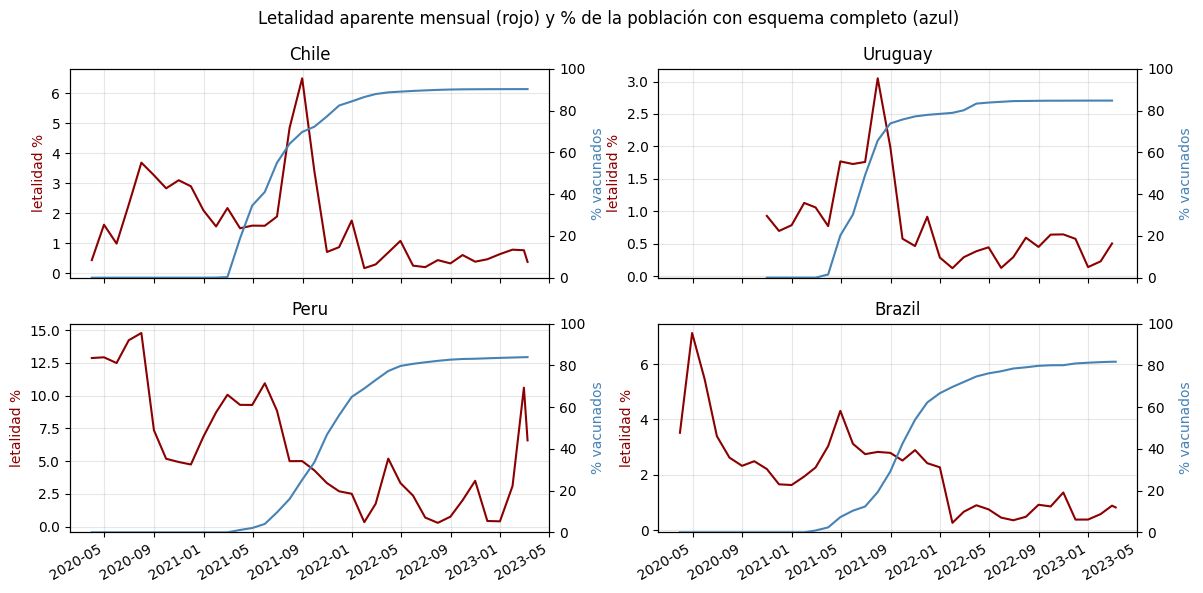

In [9]:
p3_paises = ['Chile', 'Uruguay', 'Peru', 'Brazil']
pais_dia = pd.read_sql(f"""
    SELECT t.pais, d.fecha, d.anio, d.mes,
           SUM(f.casos_acum) AS casos_acum, SUM(f.fallecidos_acum) AS fallecidos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE t.pais IN {tuple(p3_paises)} AND f.archivo_defectuoso = 0
    GROUP BY t.pais, d.fecha
""", dw)
pais_dia = pais_dia.sort_values(['pais', 'fecha'])
pais_dia['casos_nuevos'] = pais_dia.groupby('pais')['casos_acum'].diff()
pais_dia['fallecidos_nuevos'] = pais_dia.groupby('pais')['fallecidos_acum'].diff()

# Cargas de rezago en fallecidos (misma regla que en 04): no son muertes de ese mes y se dejan fuera
media_previa = pais_dia.groupby('pais')['fallecidos_nuevos'].transform(lambda s: s.rolling(7).mean().shift(1))
pais_dia['carga_rezago'] = (pais_dia['fallecidos_nuevos'] > 5 * media_previa) & (pais_dia['fallecidos_nuevos'] > 500)
print('Cargas de rezago excluidas:')
print(pais_dia.loc[pais_dia['carga_rezago'], ['pais', 'fecha', 'fallecidos_nuevos']].to_string(index=False))

mensual = pais_dia[~pais_dia['carga_rezago']].groupby(['pais', 'anio', 'mes']).agg(
    fecha=('fecha', 'max'), casos_mes=('casos_nuevos', 'sum'), fallecidos_mes=('fallecidos_nuevos', 'sum')).reset_index()
mensual['letalidad_%'] = mensual['fallecidos_mes'] / mensual['casos_mes'] * 100
mensual = mensual[mensual['casos_mes'] > 1000]    # meses con muy pocos casos dan razones inestables

# % con esquema completo al final de cada mes (desde el DW)
vac = pd.read_sql("""
    SELECT v.pais, d.anio, d.mes, MAX(v.pct_esquema_completo) AS pct_esquema_completo
    FROM fact_vacunacion v JOIN dim_fecha d ON d.fecha_key = v.fecha_key
    GROUP BY v.pais, d.anio, d.mes
""", dw)
p3 = mensual.merge(vac, on=['pais', 'anio', 'mes'], how='left')
p3['pct_esquema_completo'] = p3['pct_esquema_completo'].fillna(0)   # antes de 2021 nadie estaba vacunado
p3['fecha'] = pd.to_datetime(p3['fecha'])

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, pais in zip(axes.flat, p3_paises):
    d = p3[p3['pais'] == pais]
    ax.plot(d['fecha'], d['letalidad_%'], color='darkred', label='letalidad aparente (%)')
    ax.set_ylabel('letalidad %', color='darkred')
    ax2 = ax.twinx()
    ax2.plot(d['fecha'], d['pct_esquema_completo'], color='steelblue', label='% esquema completo')
    ax2.set_ylim(0, 100)
    ax2.set_ylabel('% vacunados', color='steelblue')
    ax.set_title(pais)
    ax.grid(alpha=0.3)
fig.suptitle('Letalidad aparente mensual (rojo) y % de la población con esquema completo (azul)')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [10]:
# Número: letalidad media antes de vacunar (< 10 % con esquema completo) y con alta cobertura (>= 70 %)
p3['etapa'] = np.select([p3['pct_esquema_completo'] < 10, p3['pct_esquema_completo'] >= 70],
                        ['antes (< 10 % vacunados)', 'después (>= 70 % vacunados)'], default='en transición')
sumas = p3.groupby(['pais', 'etapa'])[['fallecidos_mes', 'casos_mes']].sum()
sumas['letalidad_%'] = sumas['fallecidos_mes'] / sumas['casos_mes'] * 100
resumen_p3 = sumas['letalidad_%'].unstack().round(2)
resumen_p3 = resumen_p3[['antes (< 10 % vacunados)', 'en transición', 'después (>= 70 % vacunados)']]
resumen_p3

etapa,antes (< 10 % vacunados),en transición,después (>= 70 % vacunados)
pais,,,
Brazil,2.76,2.07,0.61
Chile,2.31,2.01,0.45
Peru,9.37,1.04,1.10
Uruguay,0.89,1.81,0.25


**Interpretación:** en Chile la letalidad aparente bajó de **2,3 %** antes de vacunar a **0,45 %** cuando más del 70 % tenía el esquema completo. Lo mismo ocurre en Brasil (2,8 % → 0,6 %), Perú (9,4 % → 1,1 %) y Uruguay (0,9 % → 0,25 %). La caída es grande y se repite en los cuatro países, pero no se puede atribuir solo a la vacuna:

**Advertencias (por qué esto no prueba que la vacuna bajó la letalidad):**
- La letalidad **aparente** depende de **cuántos casos se detectan**: con más testeo se encuentran más casos leves y la razón baja aunque nadie se salve.
- La caída coincide con la llegada de **ómicron** (fines de 2021), una variante menos grave: vacunación y variante se mezclan en el tiempo.
- Las muertes llegan 2 a 3 semanas después de los contagios: en meses de alza la razón del mismo mes subestima la letalidad, y en meses de baja la sobreestima.

## 7 · P7 · ¿Los países con más población de 65 años o más tuvieron mayor mortalidad?
Variable respuesta: **fallecidos acumulados por 100.000 al 9-mar-2023** (desde el DW). Filtros: países de **1 millón de habitantes o más**, con datos del Banco Mundial y con **índice de calidad ≥ 80** (sale Corea del Norte, que informa más fallecidos que casos).

In [11]:
ultimo = pd.read_sql("""
    SELECT t.pais, SUM(f.fallecidos_acum) AS fallecidos
    FROM fact_covid f JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.fecha_key = 20230309
    GROUP BY t.pais
""", dw)
p7 = pd.read_sql('SELECT * FROM dim_pais', dw).merge(ultimo, on='pais')
p7['fallecidos_x100k'] = p7['fallecidos'] / p7['poblacion'] * 100000
p7 = p7[(p7['poblacion'] >= 1000000) & p7['pob_65_pct'].notna() & p7['pib_pc_ppa'].notna() &
        (p7['indice_calidad'] >= 80)].copy()
print('Países analizados:', len(p7))

# Correlación de Spearman (usa rangos: no la mueven los valores extremos)
rho = p7['pob_65_pct'].corr(p7['fallecidos_x100k'], method='spearman')
rho_pib = p7['pib_pc_ppa'].corr(p7['fallecidos_x100k'], method='spearman')
print(f'Spearman 65+ vs fallecidos/100k: {rho:.2f} | PIB per cápita vs fallecidos/100k: {rho_pib:.2f}')

# Misma correlación dentro de cada grupo de ingreso (compara países parecidos en riqueza)
filas = []
for g, d in p7.groupby('grupo_ingreso'):
    filas.append({'grupo_ingreso': g, 'países': len(d),
                  'spearman': d['pob_65_pct'].corr(d['fallecidos_x100k'], method='spearman')})
por_grupo = pd.DataFrame(filas).set_index('grupo_ingreso').loc[['Bajo', 'Medio bajo', 'Medio alto', 'Alto']]
por_grupo.round(2)

Países analizados: 150


Spearman 65+ vs fallecidos/100k: 0.79 | PIB per cápita vs fallecidos/100k: 0.69


,países,spearman
grupo_ingreso,,
Bajo,21,0.24
Medio bajo,39,0.58
Medio alto,42,0.49
Alto,48,0.52


In [12]:
# Regresión lineal: fallecidos/100k = a + b · (% 65+), sin y con control por PIB per cápita (en log)
y = p7['fallecidos_x100k'].values
X1 = np.column_stack([np.ones(len(p7)), p7['pob_65_pct']])
X2 = np.column_stack([np.ones(len(p7)), p7['pob_65_pct'], np.log10(p7['pib_pc_ppa'])])
b1 = np.linalg.lstsq(X1, y, rcond=None)[0]
b2 = np.linalg.lstsq(X2, y, rcond=None)[0]
r2 = lambda X, b: 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()
regresion = pd.DataFrame({
    'fallecidos/100k por cada punto % de 65+': [b1[1], b2[1]],
    'R²': [r2(X1, b1), r2(X2, b2)],
}, index=['sin control', 'controlando por PIB per cápita']).round(2)
regresion

,fallecidos/100k por cada punto % de 65+,R²
sin control,14.38,0.48
controlando por PIB per cápita,12.89,0.48


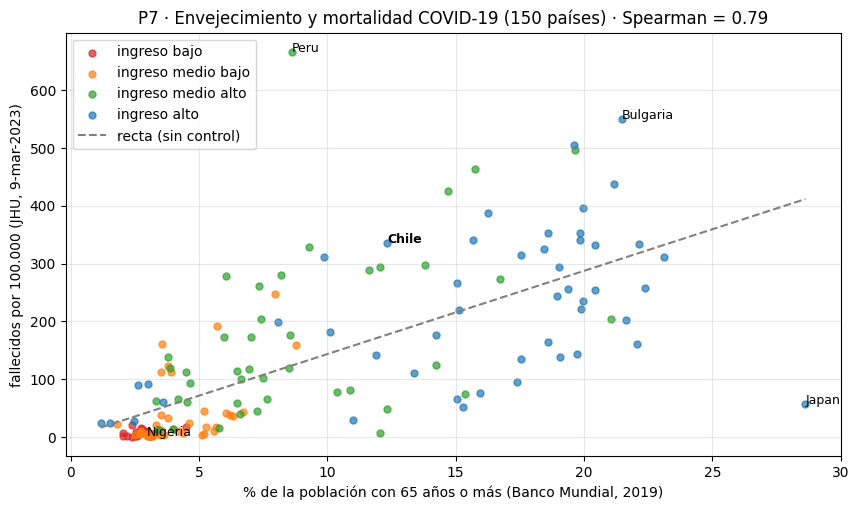

Chile: 12.3 % de 65+, 336 fallecidos por 100.000; el modelo con control esperaría 181


In [13]:
colores = {'Bajo': 'tab:red', 'Medio bajo': 'tab:orange', 'Medio alto': 'tab:green', 'Alto': 'tab:blue'}
fig, ax = plt.subplots(figsize=(10, 5.5))
for g, color in colores.items():
    d = p7[p7['grupo_ingreso'] == g]
    ax.scatter(d['pob_65_pct'], d['fallecidos_x100k'], s=25, alpha=0.7, color=color, label=f'ingreso {g.lower()}')
x = np.linspace(p7['pob_65_pct'].min(), p7['pob_65_pct'].max(), 50)
ax.plot(x, b1[0] + b1[1] * x, color='gray', linestyle='--', label='recta (sin control)')
for pais in ['Chile', 'Peru', 'Japan', 'Bulgaria', 'Nigeria']:
    fila = p7[p7['pais'] == pais]
    if len(fila) > 0:
        ax.annotate(pais, (fila['pob_65_pct'].iloc[0], fila['fallecidos_x100k'].iloc[0]),
                    fontsize=9, fontweight='bold' if pais == 'Chile' else 'normal')
ax.set_xlabel('% de la población con 65 años o más (Banco Mundial, 2019)')
ax.set_ylabel('fallecidos por 100.000 (JHU, 9-mar-2023)')
ax.set_title(f'P7 · Envejecimiento y mortalidad COVID-19 ({len(p7)} países) · Spearman = {rho:.2f}')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

chile = p7[p7['pais'] == 'Chile'].iloc[0]
pred_chile = b2[0] + b2[1] * chile['pob_65_pct'] + b2[2] * np.log10(chile['pib_pc_ppa'])
print(f"Chile: {chile['pob_65_pct']:.1f} % de 65+, {chile['fallecidos_x100k']:.0f} fallecidos por 100.000; "
      f"el modelo con control esperaría {pred_chile:.0f}")

**Interpretación:** sí. En 150 países, los más envejecidos tuvieron más fallecidos por 100.000 (Spearman **0,79**). Cada punto porcentual más de población de 65+ se asocia con unos **14 fallecidos más por 100.000** (13 al controlar por PIB per cápita), y la edad explica cerca de la mitad de la diferencia entre países (R² = 0,48). Dentro de cada grupo de ingreso la relación se mantiene, pero es más débil (0,24 a 0,58): parte de la relación general es riqueza y registro. **Chile** tuvo 336 fallecidos por 100.000, muy por sobre los 181 que el modelo esperaría por su edad e ingreso; con estos datos no se puede separar cuánto es mortalidad real y cuánto es un registro más completo.

**Cautelas (correlación ≠ causalidad):**
- Es una comparación **entre países** (falacia ecológica): no dice nada sobre el riesgo de una persona mayor.
- Los países más envejecidos son más ricos y **registran mejor** sus muertes: parte de la relación es de registro. Por eso se controla por PIB per cápita y se compara dentro de cada grupo de ingreso.
- Faltan variables: vacunación, restricciones, densidad, comorbilidades, capacidad hospitalaria.

## 8 · Guardar

In [14]:
dim_pais.to_parquet(os.path.join(LIMPIOS, 'dim_pais.parquet'), index=False)
fact_vac.to_parquet(os.path.join(LIMPIOS, 'vacunacion.parquet'), index=False)
dw.close()
shutil.copy('/content/covid_dw.db', os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'))
print('DW actualizado en Drive con dim_pais y fact_vacunacion')

DW actualizado en Drive con dim_pais y fact_vacunacion
